# FBA of the ΔCCM and ΔCCM + BHAC strains under light limitation

Flux balance analysis (FBA) on the iMS837 genome-scale model of *S. elongatus* PCC 7942 (Santos-Merino et al., 2023), comparing the ΔCCM strain with and without the BHAC:
- under non-limited and light-limited conditions,
- at two carboxylation-to-oxygenation (C:O) ratios of Rubisco (3:1 and 1:1),
- with and without an added PEP carboxykinase reaction (PPCK).

Output: one csv per C:O ratio and model variant, and SI Fig. 2.

In [1]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

## Settings

In [2]:
BASE_FOLDER = '../'
INPUT_FOLDER = f'{BASE_FOLDER}1_data/'
RESULTS_FOLDER = f'{BASE_FOLDER}3_results/'

palette = ['#dcdcdcff', '#808080ff', '#d17ca6ff']

ratios = [3, 1]                                   # C:O ratios of Rubisco (carboxylations per oxygenation)
variants = {'iMS837': '', 'iMS837 + PEPCK': '_PPCK'}

## Model construction

- **Medium:** nitrate as sole nitrogen source; carbon enters only as CO₂ (no HCO₃⁻ uptake); other inorganic nutrients unconstrained.
- **ΔCCM:** carboxysome reactions removed; cytosolic Rubisco with a fixed C:O ratio, and cytosolic carbonic anhydrase.
- **Cofactors:** NAD(P) transhydrogenase (NADTRHD) blocked, to prevent free interconversion of NADH and NADPH.
- **ΔCCM + BHAC:** the four BHAC reactions (BhcA–D) added to the ΔCCM model.
- **PEPCK variant:** OAA + ATP → PEP + CO₂ + ADP added to both strains.

In [3]:
NUTRIENTS = ['EX_pi_e', 'EX_na1_e', 'EX_mobd_e', 'EX_fe3_e', 'EX_so4_e', 'EX_no3_e', 'EX_k_e',
             'EX_cu2_e', 'EX_mg2_e', 'EX_mn2_e', 'EX_ca2_e', 'EX_zn2_e', 'EX_cobalt2_e', 'EX_co2_e']


def set_rubisco_ratio(model, n):
    """Cytosolic Rubisco with n carboxylations per oxygenation:
    (n+1) RuBP + n CO2 + n H2O + O2 -> (2n+1) 3PG + 2PG + (2n+2) H+"""
    rxn = model.reactions.get_by_id('RBPCc')
    rxn.subtract_metabolites(rxn.metabolites)
    met = model.metabolites.get_by_id
    rxn.add_metabolites({met('rb15bp_c'): -(n + 1), met('co2_c'): -n, met('h2o_c'): -n, met('o2_c'): -1,
                         met('3pg_c'): 2 * n + 1, met('2pglyc_c'): 1, met('h_c'): 2 * n + 2})


def add_reaction(model, rid, name, stoichiometry, bounds=(-1000, 1000)):
    rxn = cobra.Reaction(rid, name=name)
    rxn.bounds = bounds
    model.add_reactions([rxn])
    rxn.add_metabolites(stoichiometry)


def add_bhac(model):
    model.add_metabolites([cobra.Metabolite('hyasp_c', formula='C4H6NO5', charge=-1,
                                            name='beta-Hydroxyaspartate', compartment='cytosol')])
    add_reaction(model, 'BhcA', 'Aspartate-glyoxylate aminotransferase',
                 {'asp__L_c': -1, 'glx_c': -1, 'oaa_c': 1, 'gly_c': 1})
    add_reaction(model, 'BhcC', 'beta-Hydroxyaspartate aldolase',
                 {'glx_c': -1, 'gly_c': -1, 'hyasp_c': 1})
    add_reaction(model, 'BhcB', 'beta-Hydroxyaspartate dehydratase',
                 {'hyasp_c': -1, 'iasp_c': 1, 'h2o_c': 1, 'h_c': 1})
    add_reaction(model, 'BhcD', 'Iminosuccinate reductase',
                 {'iasp_c': -1, 'nadh_c': -1, 'h_c': -2, 'asp__L_c': 1, 'nad_c': 1}, bounds=(0, 1000))


def build_models(ratio, ppck=False):
    """Returns the ΔCCM and ΔCCM + BHAC models for a given C:O ratio."""
    model = cobra.io.load_json_model(f'{INPUT_FOLDER}iMS837.json')

    ## medium
    model.reactions.EX_nh4_e.lower_bound = 0
    model.reactions.EX_hco3_e.lower_bound = 0
    for rid in NUTRIENTS:
        model.reactions.get_by_id(rid).lower_bound = -100

    ## ΔCCM: remove carboxysome, add cytosolic Rubisco and carbonic anhydrase
    rxn_cx = {r for r in model.reactions for m in r.metabolites if 'carboxyzome' in m.compartment}
    model.remove_reactions([r.id for r in rxn_cx], remove_orphans=True)
    add_reaction(model, 'RBPCc', 'Rubisco (cytosol)', {}, bounds=(0, 1000))
    set_rubisco_ratio(model, ratio)
    add_reaction(model, 'HCO3c', 'Carbonic anhydrase (cytosol)',
                 {'h_c': -1, 'hco3_c': -1, 'co2_c': 1, 'h2o_c': 1})

    ## objective, cofactors, solver
    model.objective = 'BOF'
    model.reactions.NADTRHD.bounds = (0, 0)
    model.solver.configuration.tolerances.feasibility = 1e-9

    if ppck:
        add_reaction(model, 'PPCK', 'Phosphoenolpyruvate carboxykinase (ATP)',
                     {'oaa_c': -1, 'atp_c': -1, 'pep_c': 1, 'co2_c': 1, 'adp_c': 1}, bounds=(0, 1000))

    model_dccm = model.copy()
    add_bhac(model)
    return model_dccm, model

## FBA

- **Non-limited:** CO₂ uptake fixed at 10 mmol gDW⁻¹ h⁻¹, no light constraint.
- **Light-limited:** CO₂ uptake up to 10 mmol gDW⁻¹ h⁻¹; PSI and PSII charge separation (PSICSum, PSIICSum) each capped at 1 mmol gDW⁻¹ h⁻¹.

Net CO₂ uptake = CO₂ uptake − HCO₃⁻ export. Light use efficiency = net CO₂ uptake / (PSICSum + PSIICSum).

In [4]:
CONDITIONS = {'non-limited':   {'co2_bounds': (-10, -10), 'ps_ub': None},
              'light-limited': {'co2_bounds': (-10, 0),   'ps_ub': 1}}


def run_fba(models, ratio):
    results = []
    for strain, m in models.items():
        for cond, c in CONDITIONS.items():
            with m:  # bounds are restored after the block
                m.reactions.EX_co2_e.bounds = c['co2_bounds']
                if c['ps_ub'] is not None:
                    m.reactions.PSICSum.upper_bound = c['ps_ub']
                    m.reactions.PSIICSum.upper_bound = c['ps_ub']
                sol = m.optimize()
                ok = sol.status == 'optimal'
                mu = sol.objective_value if ok else np.nan
                net_c = (-sol.fluxes['EX_co2_e'] - sol.fluxes['EX_hco3_e']) if ok else np.nan
                cs = (sol.fluxes['PSICSum'] + sol.fluxes['PSIICSum']) if ok else np.nan
                results.append({'rubisco_ratio': ratio, 'strain': strain, 'condition': cond,
                                'growth_rate': mu, 'net_C_uptake': net_c, 'charge_separation': cs,
                                'net_C_per_CS': net_c / cs if ok and cs > 0 else np.nan,
                                'status': sol.status})
    return pd.DataFrame(results)


dfs = []
for ratio in ratios:
    for variant, suffix in variants.items():
        model_dccm, model_bhac = build_models(ratio, ppck=(suffix == '_PPCK'))
        df = run_fba({'dCCM': model_dccm, 'BHAC': model_bhac}, ratio)
        df.to_csv(f'{RESULTS_FOLDER}yield_dCCM_BHAC_ratio{ratio}{suffix}.csv', index=False)
        dfs.append(df.assign(variant=variant))
df_all = pd.concat(dfs, ignore_index=True)

## growth rates (1/h): identical between strains when not limited
df_all.pivot_table(index=['variant', 'rubisco_ratio', 'condition'], columns='strain', values='growth_rate')

Set parameter Username
Set parameter LicenseID to value 2749904

--------------------------------------------
--------------------------------------------

Academic license - for non-commercial use only - expires 2026-12-04
Read LP format model from file /tmp/tmpc8h2ian9.lp
Reading time = 0.00 seconds
: 793 rows, 1760 columns, 8010 nonzeros
Read LP format model from file /tmp/tmpntuhuelx.lp
Reading time = 0.00 seconds
: 793 rows, 1762 columns, 8020 nonzeros
Read LP format model from file /tmp/tmpcfr_6gmc.lp
Reading time = 0.01 seconds
: 793 rows, 1760 columns, 8010 nonzeros
Read LP format model from file /tmp/tmpm1_11lkl.lp
Reading time = 0.00 seconds
: 793 rows, 1762 columns, 8020 nonzeros


strain                                          BHAC      dCCM
variant        rubisco_ratio condition                        
iMS837         1             light-limited  0.001373  0.001369
                             non-limited    0.256716  0.256716
               3             light-limited  0.002817  0.002799
                             non-limited    0.256716  0.256716
iMS837 + PEPCK 1             light-limited  0.001401  0.001369
                             non-limited    0.256716  0.256716
               3             light-limited  0.002823  0.002799
                             non-limited    0.256716  0.256716

## SI Fig. 2: light use efficiency of the ΔCCM + BHAC strain relative to ΔCCM

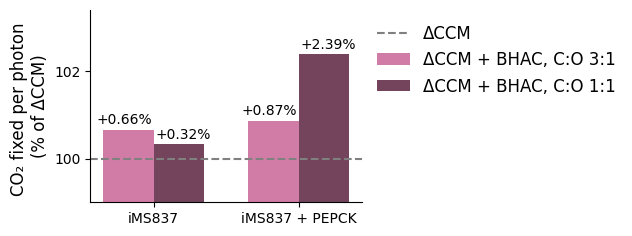

In [ ]:
def relative_efficiency(variant, ratio):
    """CO2 fixed per charge separation of the BHAC strain, in % of ΔCCM (light-limited)."""
    ll = df_all[(df_all['variant'] == variant) & (df_all['rubisco_ratio'] == ratio)
                & (df_all['condition'] == 'light-limited')].set_index('strain')
    return ll.loc['BHAC', 'net_C_per_CS'] / ll.loc['dCCM', 'net_C_per_CS'] * 100


base = to_rgb(palette[2])
bar_specs = [('ΔCCM + BHAC, C:O 3:1', base, 3),
             ('ΔCCM + BHAC, C:O 1:1', tuple(0.55 * c for c in base), 1)]
variants = {'iMS837': '', 'iMS837 + PEPCK': '_PPCK'}
x = np.arange(len(variants))
w = 0.35

fig, ax = plt.subplots(figsize=(3.5, 2.5))
all_vals = []
for j, (label, color, ratio) in enumerate(bar_specs):
    vals = [relative_efficiency(v, ratio) for v in variants]
    all_vals += vals
    bars = ax.bar(x + (j - 0.5) * w, vals, w, color=color, label=label)
    for bar, v in zip(bars, vals):
        ax.annotate(f'{v - 100:+.2f}%', xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(-3 if j == 0 else 3, 2), textcoords='offset points',
                    ha='center', va='bottom', fontsize=10)
ax.axhline(100, color=palette[1], ls='--', lw=1.5, label='ΔCCM')   # reference
## format
ax.set_xticks(x)
ax.set_xticklabels(list(variants), fontsize=10)
ax.set_ylabel('CO₂ fixed per photon \n(% of ΔCCM)', fontsize=12)
ax.set_ylim(99, max(all_vals) + 0.3 * (max(all_vals) - 99))
ax.legend(frameon=False, fontsize=12, bbox_to_anchor=(1, 1), loc='upper left')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.locator_params(axis='y', nbins=3)

# fig.savefig(f'{RESULTS_FOLDER}Figures/SI_Fig2_light_efficiency_dCCM_BHAC.svg', bbox_inches='tight', dpi=300)
# fig.savefig(f'{RESULTS_FOLDER}Figures/SI_Fig2_light_efficiency_dCCM_BHAC.jpg', bbox_inches='tight', dpi=300)